# Visualizing Linear Anti-Aliasing Between Two Points

In this example we will use WxData to:

1) Download the latest Observed Sounding Data for OUN
2) Use Matplotlib to plot Temperature vs. Pressure without Linear Anti-Aliasing
3) Use `linear_anti_aliasing()` to interpolate 100 data points between each data point in the observed sounding data
4) Use Matplotlib to plot Temperature vs. Pressure with LinearAnti-Aliasing

# Imports

In [1]:
import matplotlib.pyplot as plt

from wxdata import(
    get_observed_sounding_data,
    linear_anti_aliasing
)

# Use `get_observed_sounding_data()` To Retrieve Latest OUN Sounding Data

In [2]:
df, date = get_observed_sounding_data('oun')

In [3]:
df

,PRES,HGHT,TEMP,DWPT,RH,MIXR,DRCT,SKNT,U-WIND,V-WIND,THETA,BVF,WET-BULB
1,976.9,356,24.9,18.5,68,13.86,172,3.0,-0.417519,2.970804,300.046866,0.007355,20.400915
2,976.3,361,24.9,18.5,68,13.84,174,3.4,-0.355397,3.381374,300.099540,0.017677,20.400101
3,975.9,365,24.9,18.4,67,13.79,174,3.6,-0.376302,3.580279,300.134679,0.016944,20.335402
6,974.6,376,24.8,18.3,67,13.69,172,4.2,-0.584527,4.159126,300.148270,0.016956,20.241176
7,974.0,382,24.8,18.3,67,13.68,172,4.4,-0.612362,4.357180,300.201086,0.016961,20.240346
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3325,100.5,16443,-68.0,-85.4,7,0.00,228,24.0,17.835476,16.059135,395.518619,0.027987,-68.091002
3326,100.4,16453,-67.8,-85.3,7,0.00,228,24.0,17.835476,16.059135,396.016833,0.027993,-67.893691
3327,100.3,16458,-67.8,-85.2,7,0.00,228,24.0,17.835476,16.059135,396.129602,0.023637,-67.893655
3328,100.2,16463,-67.8,-85.2,7,0.00,228,24.0,17.835476,16.059135,396.242516,0.023649,-67.893747


In [4]:
date

datetime.datetime(2026, 10, 30, 0, 0)

# Plot the Raw Observed Temperature vs. Pressure Data With Matplotlib

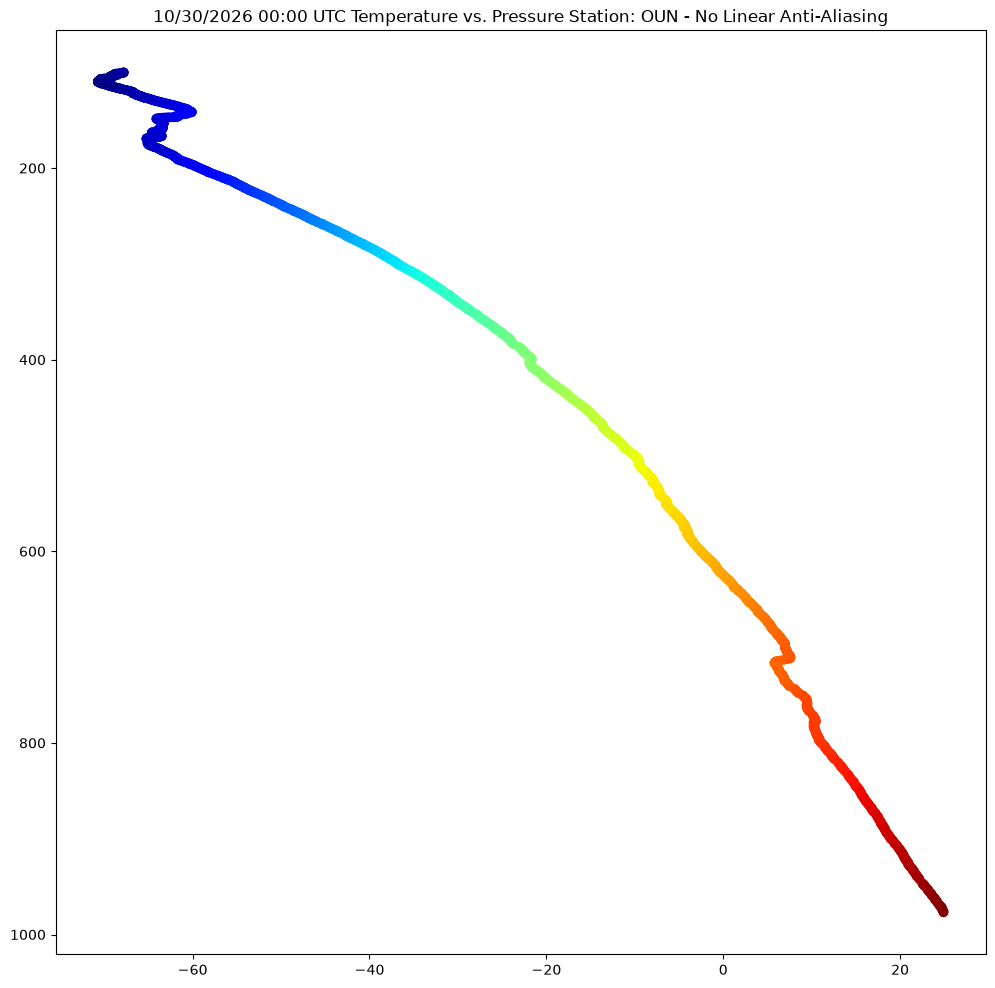

In [5]:
# Create figure object
fig = plt.figure(figsize=(12,12))

# Create out axis for our plot
ax = fig.add_subplot(1,1,1)

# Create Out Title
ax.set_title(f"{date.strftime('%m/%d/%Y %H:00 UTC')} Temperature vs. Pressure Station: OUN - No Linear Anti-Aliasing")

# Invert our y-axis
ax.invert_yaxis()

# Plot our data
ax.scatter(df['TEMP'], 
           df['PRES'], 
           c=df['TEMP'],
           cmap='jet')

# Using `linear_anti_aliasing()` From WxData

We will now use `linear_anti_aliasing()` to interpolate 100 data points between each observed point

In [6]:
anti_aliasing = 100

temp_x, temp_y = linear_anti_aliasing(df['TEMP'], 
                                     df['PRES'], 
                                     anti_aliasing)

In [7]:
temp_x

array([ 24.9,  24.9,  24.9, ..., -67.8, -67.8, -67.8], shape=(207300,))

In [8]:
temp_y

array([976.9       , 976.89393939, 976.88787879, ..., 100.1020202 ,
       100.1010101 , 100.1       ], shape=(207300,))

# Plot the Raw Observed Temperature With Linear Anti-Aliasing vs. Pressure Data With Matplotlib

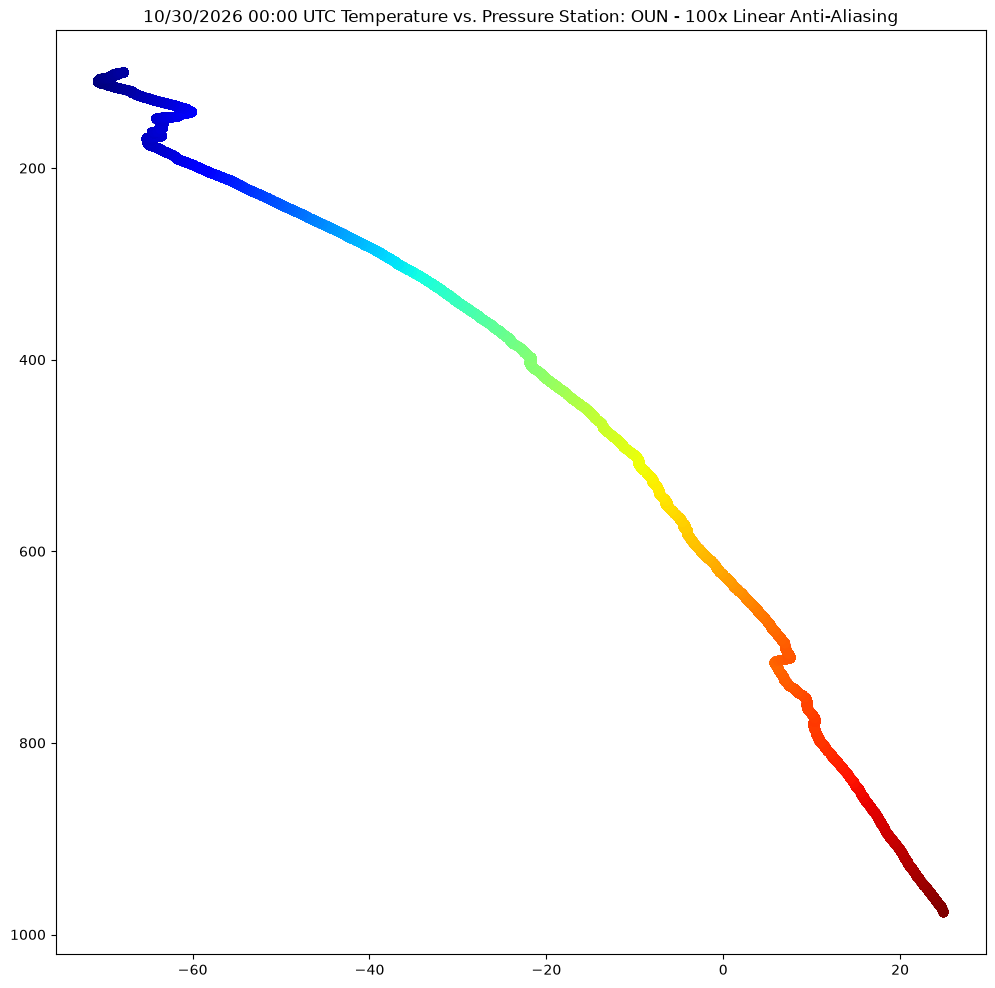

In [9]:
# Create figure object
fig = plt.figure(figsize=(12,12))

# Create out axis for our plot
ax = fig.add_subplot(1,1,1)

# Create Out Title
ax.set_title(f"{date.strftime('%m/%d/%Y %H:00 UTC')} Temperature vs. Pressure Station: OUN - 100x Linear Anti-Aliasing")

# Invert our y-axis
ax.invert_yaxis()

# Plot our data
ax.scatter(temp_x, 
           temp_y, 
           c=temp_x,
           cmap='jet')